# 2. Premier HMM : 2 états sur les rendements

Un Hidden Markov Model suppose que le marché passe d'un régime caché à l'autre, et que chaque régime a sa propre loi de rendements. On commence par le cas le plus simple : 2 états, une seule variable.

⚠️ Dans ce notebook, le modèle est entraîné sur toute la période et décodé avec `predict()`, qui regarde le futur. C'est de l'exploration : on corrige ça aux notebooks 3 et 4.

In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

# Remonte jusqu'au dossier qui contient src/, quel que soit l'endroit d'où on lance
root = Path.cwd()
while not (root / "src").is_dir() and root != root.parent:
    root = root.parent
sys.path.insert(0, str(root))
DATA = root / "data"

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.data import download_prices
from src.models import expected_durations, fit_hmm, stationary_distribution

df = pd.read_parquet(DATA / "features.parquet")

## 2.1 Entraînement

On multiplie les rendements par 100 (en %) pour que l'optimisation soit numériquement plus stable.

In [3]:
X = df[["ret"]].values * 100

model = fit_hmm(X, 2, random_state=42)
raw_states = model.predict(X)

# Ordre des états par variance croissante : 0 = calme, 1 = agité
order = np.argsort(model.covars_[:, 0, 0])
mapping = np.empty_like(order)
mapping[order] = np.arange(2)
states = mapping[raw_states]
T = model.transmat_[np.ix_(order, order)]

In [4]:
names = ["calme", "agité"]

for i, k in enumerate(order):
    mean = model.means_[k, 0]           # rendement quotidien moyen, en %
    variance = model.covars_[k, 0, 0]   # variance quotidienne, en %²
    print(f"{names[i]:>6} : rendement annualisé {mean / 100 * 252:+.1%}, "
          f"volatilité annualisée {np.sqrt(variance) / 100 * np.sqrt(252):.1%}, "
          f"{(states == i).mean():.0%} des jours")

 calme : rendement annualisé +20.0%, volatilité annualisée 11.2%, 73% des jours
 agité : rendement annualisé -29.2%, volatilité annualisée 31.1%, 27% des jours


In [5]:
print("Matrice de transition :")
print(pd.DataFrame(T, index=names, columns=names).round(4))

print("\nDurée moyenne (jours) :", np.round(expected_durations(T), 1))
print("Répartition de long terme :", np.round(stationary_distribution(T), 3))
print("Nombre de changements de régime :", (np.diff(states) != 0).sum())

Matrice de transition :
        calme   agité
calme  0.9879  0.0121
agité  0.0297  0.9703

Durée moyenne (jours) : [82.9 33.7]
Répartition de long terme : [0.711 0.289]
Nombre de changements de régime : 63


**Vérifications :**

- les termes diagonaux de la matrice dépassent 0,97 : les régimes durent des semaines ou des mois ;
- la répartition de long terme tirée de la matrice est proche de la part des jours dans chaque état : paramètres et décodage racontent la même histoire ;
- on attend quelques changements par an, pas des centaines (sinon le décodage « clignote »).

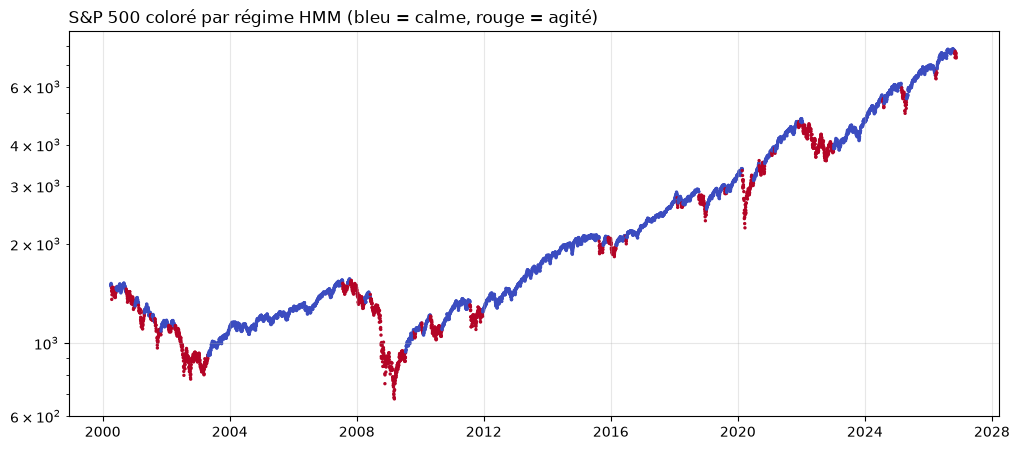

In [6]:
prices = download_prices("^GSPC").loc[df.index]

fig, ax = plt.subplots(figsize=(12, 5))
ax.scatter(df.index, prices, c=states, cmap="coolwarm", s=2)
ax.set_yscale("log")
ax.set_title("S&P 500 coloré par régime HMM (bleu = calme, rouge = agité)", loc="left")
ax.grid(alpha=0.3)
plt.show()

## Le piège

L'écart de rendement entre les deux états est **trop beau pour être exploitable** :

1. `predict()` utilise toute la série (algorithme de Viterbi) : pour classer un jour, il s'appuie aussi sur les jours suivants. Les jours qui précèdent une chute sont rangés après coup dans l'état agité.
2. Le modèle est entraîné sur toute la période, y compris les crises qu'il est censé détecter.

Ces deux biais sont traités dans les notebooks 3 (probabilités filtrées) et 4 (walk-forward).